# Probabilidad Laplaciana

Para un experimento aleatorio, se tiene que $\Omega$ es el espacio muestral (el conjunto de posibles resultados).

Sea $A$ un evento, entonces definimos la probabilidad de $A$ como sigue:

$$ \mathbb{P}(A) = \frac{|A|}{|\Omega|} $$

## *Ejemplo:*
Sea el experimento de lanzar una moneda 3 veces, de manera independiente, es decir, el $i$-ésimo lanzamiento no afecta al $i+1$ lanzamiento. Entonces el espacio muestral asociado a este experimento es:

$$ \Omega = \{A, S\} \times \{A, S\} \times \{A, S\} = \{A, S\}^3 $$
donde 
$A = \{\text{águilas}\} , A = \{\text{soles}\} $ y sabemos que $|\Omega|=2^3=8$

Sean los eventos: 

-$A$: todos los resultados son aguila

-$S$: todos los resultados son sol

-$E$: por lo menos un resultado es sol (1 o 2 o 3 soles)

Calcular las probabilidades por medio de la probabilidad laplaciana.
Para hacer esto, vamos a descomponer el evento $A$ de la siguiente manera:  

$$ A= A_1 \cap A_2 \cap A_3 $$

donde $A_i$ es que caiga águila en el $i$-ésimo lanzamiento.

In [46]:
import itertools
from itertools import product
from fractions import Fraction
from collections import defaultdict
import pandas as pd
import matplotlib

In [7]:
Omega= set(product(('A','S'),repeat=3)) # set convierte en conjunto y product e
Omega

{('A', 'A', 'A'),
 ('A', 'A', 'S'),
 ('A', 'S', 'A'),
 ('A', 'S', 'S'),
 ('S', 'A', 'A'),
 ('S', 'A', 'S'),
 ('S', 'S', 'A'),
 ('S', 'S', 'S')}

In [8]:
len(Omega)

8

In [9]:
# Para A_1 : el primer elemento es águila
A_1 = { om for om in Omega if om[0]=='A' }
A_1

{('A', 'A', 'A'), ('A', 'A', 'S'), ('A', 'S', 'A'), ('A', 'S', 'S')}

In [10]:
# Para A_2 : el segundo elemento es águila
A_2 = { om for om in Omega if om[1]=='A' }
A_2

{('A', 'A', 'A'), ('A', 'A', 'S'), ('S', 'A', 'A'), ('S', 'A', 'S')}

In [11]:
# Para A_3 : el tercer elemento es águila
A_3 = { om for om in Omega if om[2]=='A' }
A_3

{('A', 'A', 'A'), ('A', 'S', 'A'), ('S', 'A', 'A'), ('S', 'S', 'A')}

In [12]:
#intersectar A1, A2 y A3
A=A_1.intersection(A_2).intersection(A_3)
A


{('A', 'A', 'A')}

In [13]:
card_a = len(A)

In [14]:
P_A=card_a/len(Omega)   
P_A

0.125

Utilizamos fractions para resultado en fracción

In [15]:
#funcion de probabilidad
def p(E, Omega):
    P=len(E)/len(Omega)
    #Fraction(len(E)/len(Omega))
    return P



In [16]:
Prop_A=p(A, Omega)

In [17]:
print(Prop_A)

0.125


## Probabilidad condicional

Si añadimos información condiciones a nuestro experimento aleatorio, entonces la probabilidad de un evento cambia.

Definamos la *probabilidad condicional* de que ocurra un evento $A$ sabiendo que ocurre un evento $B$ de probabilidad positiva, entonces

$$ \mathbb{P}(A \mid B ) = \frac{\mathbb{P}(A\cap B)}{\mathbb{P}(B)} = \frac{|A\cap B|}{|B|} $$

# Vamos a definir la función de probabilidad condicional

def prob_cond(E, F):
    return len(E & F) / len(F)

Queremos calcular la probabilidad condicional de los siguientes eventos:

- $B$: el primer lanzamiento es águila
- $C$: dos de los resultados son águila (exactamente)

Quiero calcular $\mathbb{P}(B\mid C)$

In [18]:
def prob_cond(B, C):
    P_B = p(B, Omega)
    P_C = p(C, Omega)
    P_BC = p(B.intersection(C), Omega)
    
    if P_C == 0:
        return "La probabilidad de C es cero, no se puede calcular la probabilidad condicional."
    
    P_B_given_C = P_BC / P_C
    return P_B_given_C


In [19]:
# Para el evento B : el primer lanzamiento es águila

B = { om for om in Omega if om[0]=='A'}
B

{('A', 'A', 'A'), ('A', 'A', 'S'), ('A', 'S', 'A'), ('A', 'S', 'S')}

In [20]:
# Para el evento C: dos de los resultados son águila

C = {om for om in Omega if om.count('A')==2}
C

{('A', 'A', 'S'), ('A', 'S', 'A'), ('S', 'A', 'A')}

In [21]:
#Calcular la probabilidad de P(B|C)
prob_cond(B, C)

0.6666666666666666

In [22]:
prob_cond(C, B)

0.5

## Independencia de eventos

Decimos que dos eventos $A$ y $B$ son independiente si 
$$\mathbb{P}(A\cap B)=\mathbb{P}(A){P}(B)$$

In [23]:
def prob(E):
    return len(E)/len(Omega)

In [24]:
#Definimos la funcion de independencia de eventos
def indep(E,F):
    return prob(E & F) == prob(E)*prob(F)

In [25]:
# Son B y C independientes?
indep(B, C)

False

# Ejemplo. Lanzamiento de un dado honesto 2 veces

Sea el experimento aleatorio de lanzar  un dado honesto 2 veces, entonces sabemos que el espacio muestral es de la siguiente forma :

$$ \Omega = \{ (i,j) \mid i,j\in\{1,2,3,4,5,6\} \} $$
y ademas $$\|\Omega\|=6^2=36$$

In [26]:
#Vamos a definir el espacio muestral para el experimento de lanzmiento de dos dados.
Omega=set(product(range(1,7), repeat=2))
Omega

{(1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (1, 5),
 (1, 6),
 (2, 1),
 (2, 2),
 (2, 3),
 (2, 4),
 (2, 5),
 (2, 6),
 (3, 1),
 (3, 2),
 (3, 3),
 (3, 4),
 (3, 5),
 (3, 6),
 (4, 1),
 (4, 2),
 (4, 3),
 (4, 4),
 (4, 5),
 (4, 6),
 (5, 1),
 (5, 2),
 (5, 3),
 (5, 4),
 (5, 5),
 (5, 6),
 (6, 1),
 (6, 2),
 (6, 3),
 (6, 4),
 (6, 5),
 (6, 6)}

Definimos el evento 
- $S_n$: La suma de los dados es $n$

donde n\in\{2,3,\dots,12}$

$$S_n= \{ (i,j)\in\Omega \mid i+j=n\}$$

In [27]:
#Definimos Sn 
def S(n):
    Sn={ (i,j)for i in range(1,7) for j in range(1,7) if i+j==n} #Condición que define cuando nuestro evento se cumple, trasladamos la condición a un conjunto por comprensión
    return Sn

In [28]:
S_nueve=S(9)
S_nueve

{(3, 6), (4, 5), (5, 4), (6, 3)}

In [29]:
S_cinco=S(5)
S_cinco

{(1, 4), (2, 3), (3, 2), (4, 1)}

In [30]:
def P(A):
    P=Fraction(len(A), len(Omega))
    return P


Vamos a agrupar combinaciones por suma y para esto se utiliza  `defaultdict(set) ` para crear diccionarios cuyas clabes tengan como valor un conjunto vacio por defecto.

**Nota.** Es útil cuando queremos agrupar resultados sin tener que verificar primero si la llave existe en el diccionario.{llave:valor}

In [31]:
#Agrupamos por sumas
#Recorrer y agrupar por suma
dSn=defaultdict(set)


In [32]:
Sn={(i,j) : i+j for i,j in Omega}
Sn

{(3, 4): 7,
 (4, 3): 7,
 (3, 1): 4,
 (5, 4): 9,
 (4, 6): 10,
 (5, 1): 6,
 (2, 2): 4,
 (1, 6): 7,
 (2, 5): 7,
 (1, 3): 4,
 (6, 2): 8,
 (6, 5): 11,
 (4, 2): 6,
 (4, 5): 9,
 (3, 3): 6,
 (5, 6): 11,
 (3, 6): 9,
 (5, 3): 8,
 (2, 4): 6,
 (1, 2): 3,
 (2, 1): 3,
 (1, 5): 6,
 (6, 1): 7,
 (6, 4): 10,
 (3, 2): 5,
 (4, 1): 5,
 (3, 5): 8,
 (5, 2): 7,
 (4, 4): 8,
 (5, 5): 10,
 (1, 1): 2,
 (1, 4): 5,
 (2, 3): 5,
 (2, 6): 8,
 (6, 6): 12,
 (6, 3): 9}

In [33]:
#Recorrer los elementos del diccionario; llaves y valores
#i : es la llave, es el par ordenado
#j: es el valor, es la suma de los elementos del par ordenado
for i,j in Sn.items():
    dSn[j].add(i) #agregar


In [34]:
list(dSn.items())

[(7, {(1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)}),
 (4, {(1, 3), (2, 2), (3, 1)}),
 (9, {(3, 6), (4, 5), (5, 4), (6, 3)}),
 (10, {(4, 6), (5, 5), (6, 4)}),
 (6, {(1, 5), (2, 4), (3, 3), (4, 2), (5, 1)}),
 (8, {(2, 6), (3, 5), (4, 4), (5, 3), (6, 2)}),
 (11, {(5, 6), (6, 5)}),
 (3, {(1, 2), (2, 1)}),
 (5, {(1, 4), (2, 3), (3, 2), (4, 1)}),
 (2, {(1, 1)}),
 (12, {(6, 6)})]

Tenemos que una variable aleatoria $X$ es una función
$$ X: \Omega \to \mathbb{R}$$
La ley de una variable aleatoria discreta (que toma valores sobre algun subconjunto discreto $\subseteq \mathbb{Z}$), y se define como sigue:

$$p_X(x)= \begin{cases} 
         \mathbb{P}(X=x), \text{ si} x\in R_X \\
         0, \quad \text{en otro caso (e.o.c)} 
         \end{cases}$$

donde $$R_X$ es el rango de la variable aleatoria $X$.

La función de densidad, cumple las siguientes propiedades:

-1. $0 \leq p_X(k) \leq 1 $
-2. $\sum_{k\in R_X} p_x(k)=1$


Para nuestro ejemplo, se tiene la siguiente v.a
$$ S_n: \Omega \to \{ 2,3, \dots,12\}$$

In [35]:
#Vamos a crear la ley de Sn, que será la probabilidad de cada suma
LeySn={i: P(A) for i,A in dSn.items()}
LeySn

{7: Fraction(1, 6),
 4: Fraction(1, 12),
 9: Fraction(1, 9),
 10: Fraction(1, 12),
 6: Fraction(5, 36),
 8: Fraction(5, 36),
 11: Fraction(1, 18),
 3: Fraction(1, 18),
 5: Fraction(1, 9),
 2: Fraction(1, 36),
 12: Fraction(1, 36)}

Pasamos al manejo con `pandas` para la manipulación y análisis de datos.

In [37]:
#Todas las librerias se han importado al inicio del notebook con el objetivo de que el código sea más limpio y ordenado.
Ley_Sn= pd.Series(LeySn)
Ley_Sn

7      1/6
4     1/12
9      1/9
10    1/12
6     5/36
8     5/36
11    1/18
3     1/18
5      1/9
2     1/36
12    1/36
dtype: object

In [38]:
#Ordenar de manera ascendente
Ley_Sn=Ley_Sn.sort_index(ascending=True)
Ley_Sn

2     1/36
3     1/18
4     1/12
5      1/9
6     5/36
7      1/6
8     5/36
9      1/9
10    1/12
11    1/18
12    1/36
dtype: object

In [39]:
#Defini la función de densidad / función de masa de probabilidad  (Ley de Sn)

def leyS(i):
    if i in range(2,13): #del 2 al 12
        x = LeySn[i] #asigne probabilidad
    else:
        x = 0   #probabilidad 0
    return x


In [40]:
# Creamos el rango de la v.a.
rango_S=[k for k in range(2,13)] #del 2 al 12      
#Obtenemos la lista de probabilidades de cada suma en el rango S
p_k=[float(leyS(k)) for k in rango_S  ]
p_k

[0.027777777777777776,
 0.05555555555555555,
 0.08333333333333333,
 0.1111111111111111,
 0.1388888888888889,
 0.16666666666666666,
 0.1388888888888889,
 0.1111111111111111,
 0.08333333333333333,
 0.05555555555555555,
 0.027777777777777776]

In [42]:
#Verificamos que la suma de las probabilidades sea 1
sum(p_k)

1.0

Vamos a crear un Df, donde los valores del rango de S ( `rango_S`) y `p_k` son las probabilidades de cada suma

In [43]:
lS= pd.DataFrame(list(zip(rango_S, p_k)), 
                 index=[f'S_{k}' for k in rango_S],
                 columns=['rango', 'densidad'])

In [44]:
lS

,rango,densidad
S_2,2,0.027778
S_3,3,0.055556
S_4,4,0.083333
S_5,5,0.111111
S_6,6,0.138889
S_7,7,0.166667
S_8,8,0.138889
S_9,9,0.111111
S_10,10,0.083333
S_11,11,0.055556


### Generamos la grafica para visualizar la densidad de la probabilidad

<Axes: title={'center': 'Distribución de probabilidad de la suma de dos dados'}, xlabel='rango'>

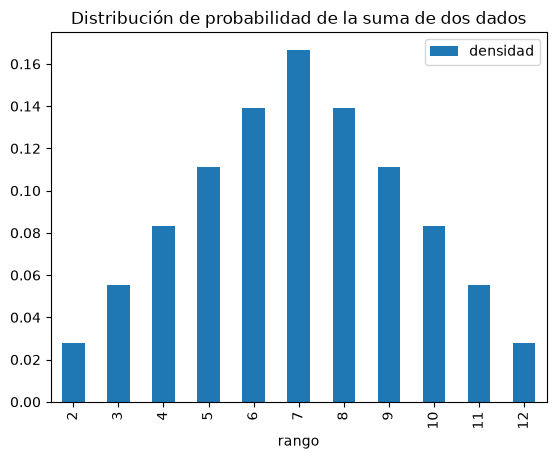

In [49]:
lS.plot.bar(x= 'rango', y='densidad', title='Distribución de probabilidad de la suma de dos dados', legend=True)